# 02 · 결과 — Tables 1–6 (Monte Carlo) 와 Figures 1–4 (실증) 원문 대비
이 노트북은 **재계산하지 않는다**. `results/` 의 저장된 실행 결과만 읽는다 (재실행은 README 의 명령).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'config' / 'paper2020_runtime.yaml').exists())
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)
import json
from IPython.display import Image, display

## 1. Monte Carlo — lane별 원문 대비 rejection rate
- `clip` = 실행 레인 (OBSERVED_PROXY, 비양수 분산 → machine-eps clip; 사전등록상 sensitivity)
- `raise` = 사전등록 primary (비양수 분산 시 해당 반복 실패; 실패는 비기각으로 계산한 `reject_rate_all` 병기)
- `recursive` = 테스트 분산 lag 를 재귀 예측으로 채우는 민감도 레인
- `status`: COMPLETE_1000 / PARTIAL_k (k 회만 실행)

In [2]:
import subprocess
subprocess.run([sys.executable, str(ROOT / 'scripts' / 'summarize_mc.py')], check=True, capture_output=True)
lanes = {l: pd.read_csv(ROOT / 'results' / f'mc_summary_{l}.csv') for l in ('clip', 'raise', 'recursive') if (ROOT / 'results' / f'mc_summary_{l}.csv').exists()}
for l, s in lanes.items():
    print(l, len(s), 'rows;', s.status.value_counts().to_dict())
lanes['clip'].pivot_table(index=['table', 'label'], columns='n', values=['reject_rate_ok', 'paper'], sort=False)

clip 124 rows; {'PARTIAL_100': 79, 'COMPLETE_1000': 45}
raise 45 rows; {'PARTIAL_100': 45}
recursive 45 rows; {'PARTIAL_100': 45}


reject_rate_ok        \
n                                                             500   1000   
table label                                                                
1     size                                                   0.000  0.00   
      omega=1                                                0.284  0.45   
      omega=0.1                                              0.692  0.99   
      alpha=0.1,beta=0.2                                     0.004  0.00   
      alpha=0.4,beta=0.5                                     0.399  0.63   
      omega=0.7,alpha=0.1                                    0.002  0.00   
      omega=0.1,beta=0.1                                     0.972  1.00   
2     size                                                   0.003  0.00   
      omega=1                                                0.039  0.11   
      omega=0.1                                              0.022  0.04   
      alpha=0.1,beta=0.1                                     0.812  0.99   
      alpha=0.6                                              0.637  0.86   
      b=0                                                    0.130  0.47   
      b=3                                                    0.567  0.87   
      omega=0.1,alpha=0.5,beta=0.4,b=0                       0.847  0.97   
      omega=0.1,beta=0.6,b=2                                 0.636  0.81   
3     size                                                   0.004  0.00   
      omega=1                                                0.259  0.46   
      omega=0.1                                              0.737  0.96   
      alpha_1=0.5,alpha_2=0.8                                0.362  0.48   
      alpha_2=0.1,beta=0.1                                   0.029  0.07   
      omega=0.5,alpha_2=0.6                                  0.114  0.15   
      omega=0.1,beta=0.7                                     0.866  0.94   
4     size                                                   0.000  0.00   
      omega=1                                                0.965  0.99   
      omega=0.1                                              0.995  1.00   
      alpha=0.1,beta=0.2                                     0.094  0.43   
      alpha=0.4,beta=0.5                                     0.914  0.98   
      omega=0.7,alpha=0.1                                    0.051  0.05   
      omega=0.1,beta=0.1                                     0.991  1.00   
5     size                                                   0.000  0.00   
      omega=1                                                0.812  0.95   
      omega=0.1                                              0.007  0.02   
      alpha=-0.1,beta=-0.2                                   0.004  0.00   
      alpha=-0.4,beta=0.5                                    0.134  0.47   
      omega=0.7,beta=0.5                                     0.934  1.00   
      omega=0.1,alpha=-0.1                                   0.001  0.00   
6     GARCH->log-GARCH omega=1                               0.969  1.00   
      GARCH->log-GARCH alpha=0.1,beta=0.1                    0.004  0.00   
      log-GARCH->GARCH omega=1                               0.023  0.03   
      log-GARCH->GARCH alpha=0.1,beta=0.1                    0.069  0.29   
      TGARCH->AGARCH omega=1,b=1                             0.941  0.96   
      TGARCH->AGARCH alpha=0.1,beta=0.1,b=1                  0.001  0.00   
      AGARCH->GJR omega=0.7,alpha_1=0.3,alpha_2=0.7          0.095  0.13   
      AGARCH->GJR alpha_1=0.1,alpha_2=0.3,beta=0.1           0.823  1.00   

                                                           paper                
n                                                    2000   500    1000   2000  
table label                                                                     
1     size                                           0.00  0.023  0.038  0.055  
      omega=1                                        0.78  0.761  0.826  0.956 

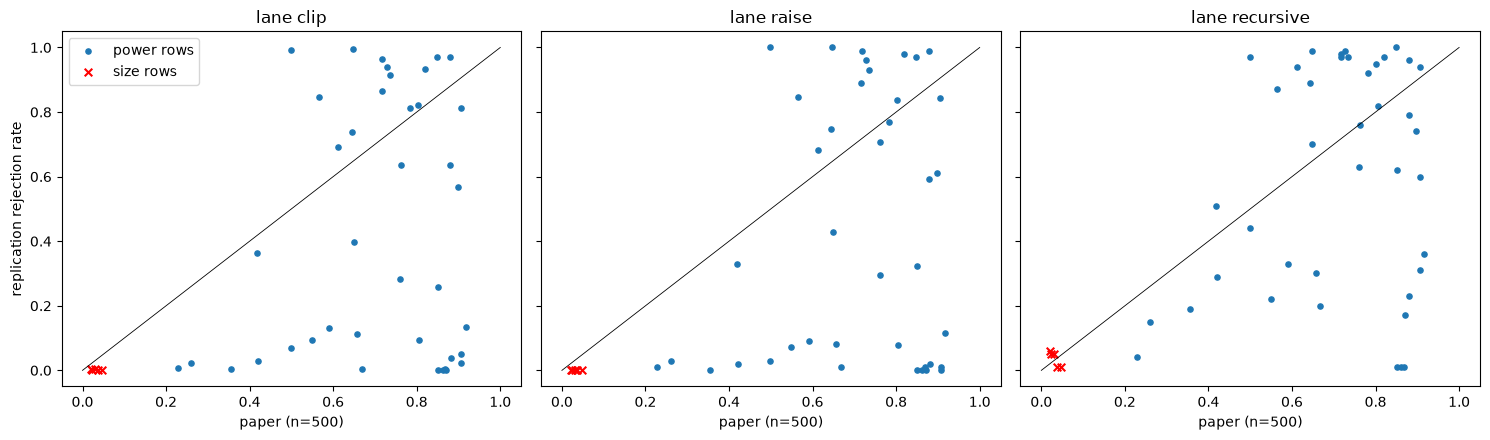

In [3]:
fig, axes = plt.subplots(1, len(lanes), figsize=(5 * len(lanes), 4.5), sharey=True)
for ax, (l, s) in zip(np.atleast_1d(axes), lanes.items()):
    s5 = s[s.n == 500]
    size = s5.label == 'size'
    ax.scatter(s5.paper[~size], s5.reject_rate_ok[~size], s=14, label='power rows')
    ax.scatter(s5.paper[size], s5.reject_rate_ok[size], s=30, marker='x', c='r', label='size rows')
    ax.plot([0, 1], [0, 1], c='k', lw=.6); ax.set_xlabel('paper (n=500)'); ax.set_title(f'lane {l}')
np.atleast_1d(axes)[0].set_ylabel('replication rejection rate'); np.atleast_1d(axes)[0].legend(); plt.tight_layout(); plt.show()

In [4]:
rows = []
for l, s in lanes.items():
    for n, g in s.groupby('n'):
        sz, pw = g[g.label == 'size'], g[g.label != 'size']
        rows.append({'lane': l, 'n': n, 'rows': len(g), 'reps/row (min)': g.reps_attempted.min(),
                     'mean size (paper)': round(sz.paper.mean(), 3), 'mean size (repl)': round(sz.reject_rate_ok.mean(), 3),
                     'mean power (paper)': round(pw.paper.mean(), 3), 'mean power (repl)': round(pw.reject_rate_ok.mean(), 3),
                     'MAE vs paper': round((g.reject_rate_ok - g.paper).abs().mean(), 3)})
pd.DataFrame(rows)

,lane,n,rows,reps/row (min),mean size (paper),mean size (repl),mean power (paper),mean power (repl),MAE vs paper
0,clip,500,45,1000,0.032,0.001,0.705,0.431,0.357
1,clip,1000,45,100,0.039,0.000,0.848,0.539,0.365
2,clip,2000,34,100,0.042,0.000,0.913,0.731,0.221
3,raise,500,45,100,0.032,0.000,0.705,0.433,0.362
4,recursive,500,45,100,0.032,0.036,0.705,0.594,0.261


## 2. 실증 (§5) — Yahoo Finance 대체 출처 (SOURCE_SUBSTITUTED; Investing.com HTTP 403)

In [5]:
emp = json.loads((ROOT / 'results' / 'empirical_summary.json').read_text())
tab = []
for name, d in emp.items():
    for lane in ('raise', 'clip', 'recursive_clip'):
        v = d.get(lane, {})
        tab.append({'series': name, 'lane': lane, 'paper_T': d['paper']['stat'], 'repl_T': v.get('statistic'),
                    'paper_date': d['paper']['date'], 'repl_date': v.get('change_date'), 'reject': v.get('reject_5pct'),
                    'svr': v.get('best_svr'), 'nonpos_var': v.get('n_nonpositive_variance')})
pd.DataFrame(tab)

,series,lane,paper_T,repl_T,paper_date,repl_date,reject,svr,nonpos_var
0,sp500,raise,2.4751,0.7540,2015-08-18,2015-06-26,False,"{'C': 1.0, 'paper_gamma_squared': 1.0, 'epsilo...",0
1,sp500,clip,2.4751,0.7540,2015-08-18,2015-06-26,False,"{'C': 1.0, 'paper_gamma_squared': 1.0, 'epsilo...",0
2,sp500,recursive_clip,2.4751,1.0963,2015-08-18,2015-08-18,False,"{'C': 1.0, 'paper_gamma_squared': 1.0, 'epsilo...",0
3,kospi,raise,1.5081,0.7910,2018-01-22,2018-03-22,False,"{'C': 10.0, 'paper_gamma_squared': 1.0, 'epsil...",0
4,kospi,clip,1.5081,0.7910,2018-01-22,2018-03-22,False,"{'C': 10.0, 'paper_gamma_squared': 1.0, 'epsil...",0
5,kospi,recursive_clip,1.5081,1.1071,2018-01-22,2017-11-24,False,"{'C': 10.0, 'paper_gamma_squared': 1.0, 'epsil...",0
6,krw_usd,raise,4.2754,0.7939,2014-09-26,2014-09-09,False,"{'C': 1.0, 'paper_gamma_squared': 0.1, 'epsilo...",0
7,krw_usd,clip,4.2754,0.7939,2014-09-26,2014-09-09,False,"{'C': 1.0, 'paper_gamma_squared': 0.1, 'epsilo...",0
8,krw_usd,recursive_clip,4.2754,1.0238,2014-09-26,2014-09-09,False,"{'C': 1.0, 'paper_gamma_squared': 0.1, 'epsilo...",0


fig1_acf_pacf_all.png


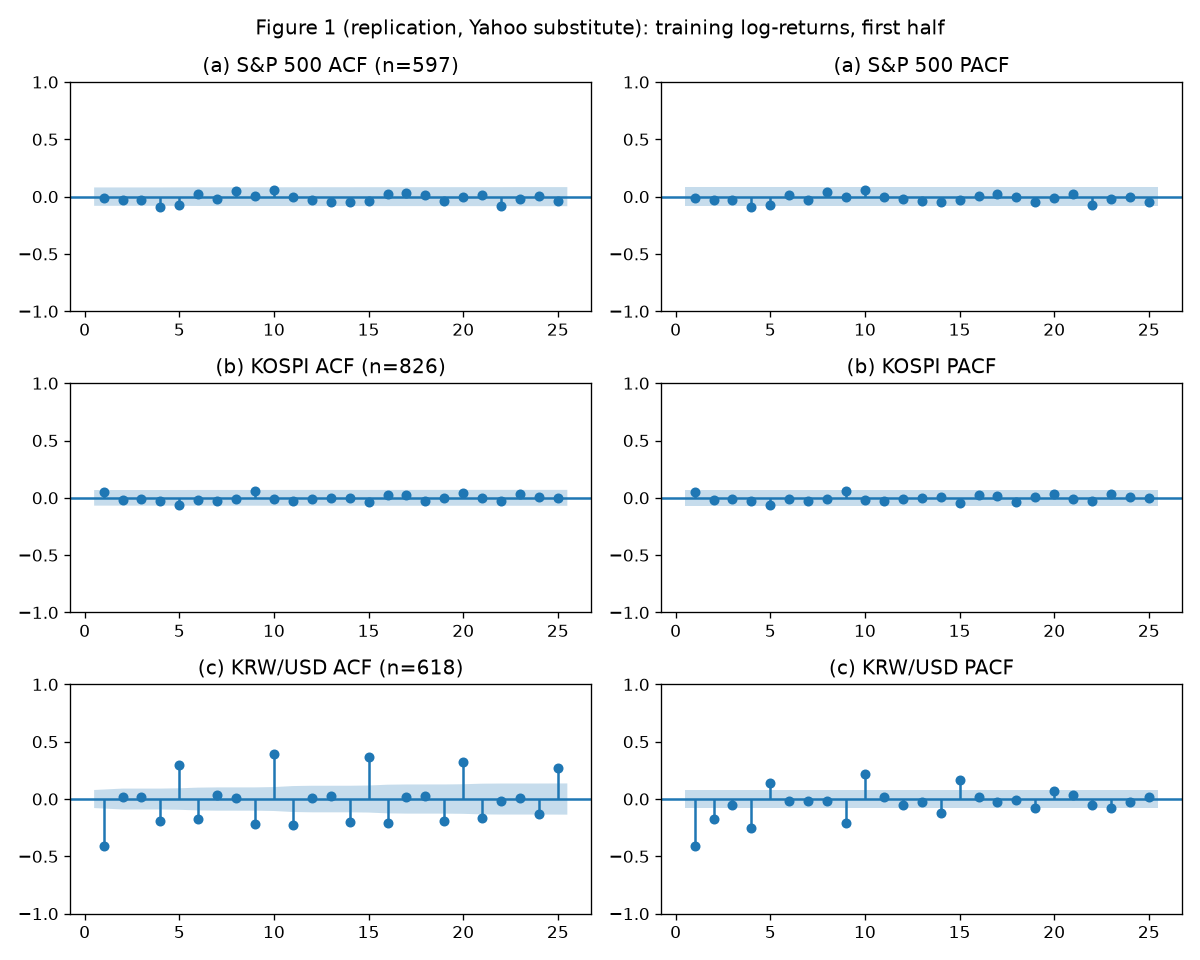

fig1_sp500_acf_pacf.png


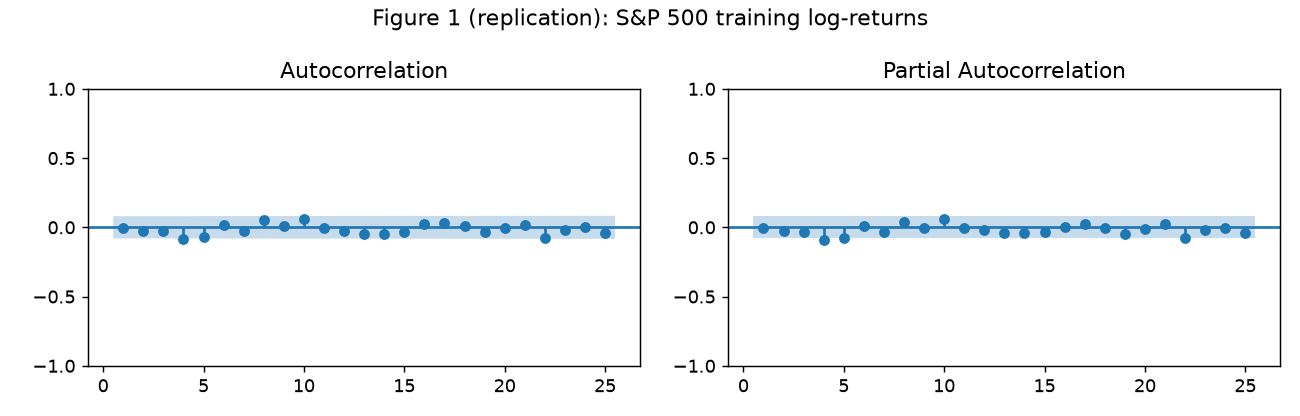

fig2_sp500.png


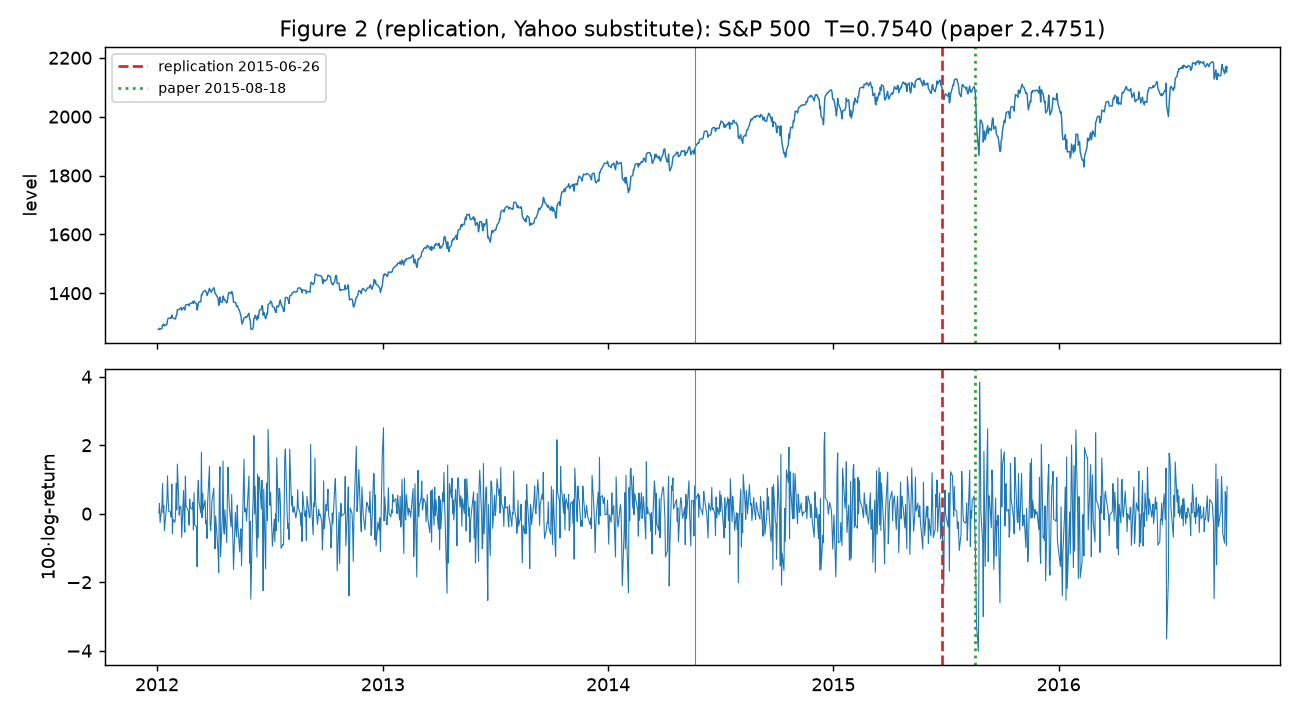

fig3_kospi.png


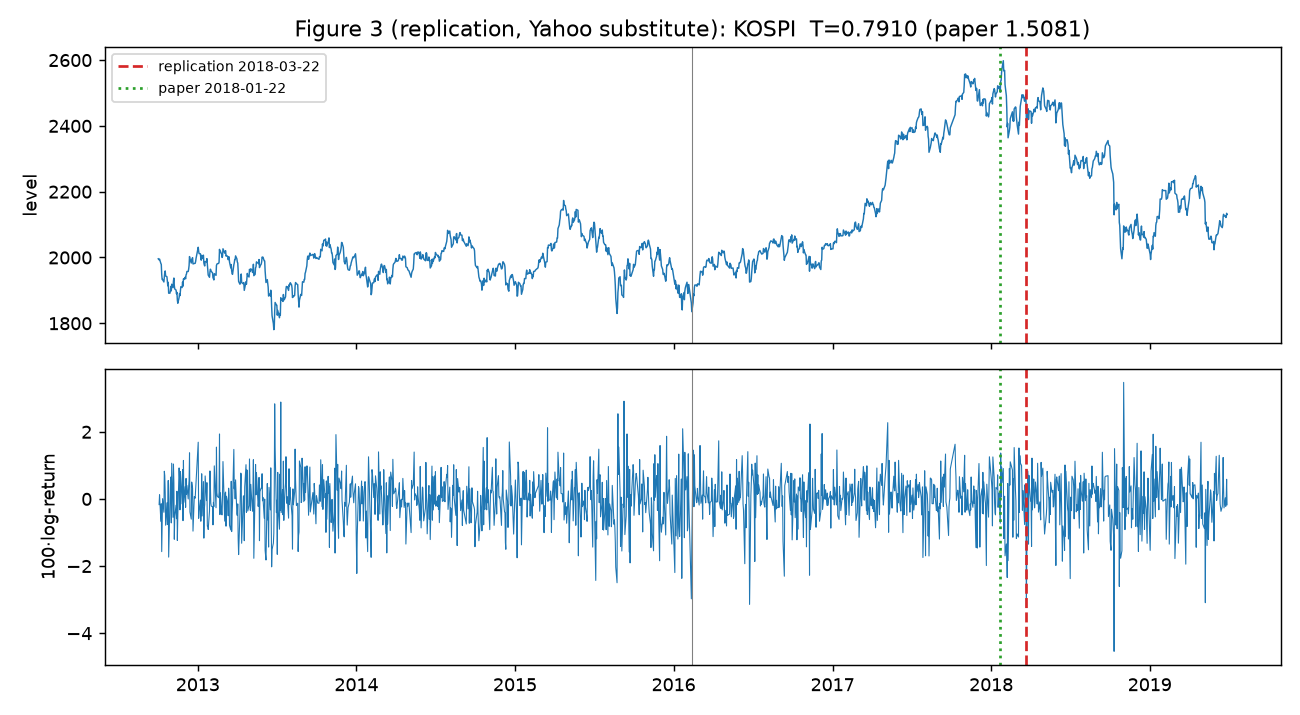

fig4_krw_usd.png


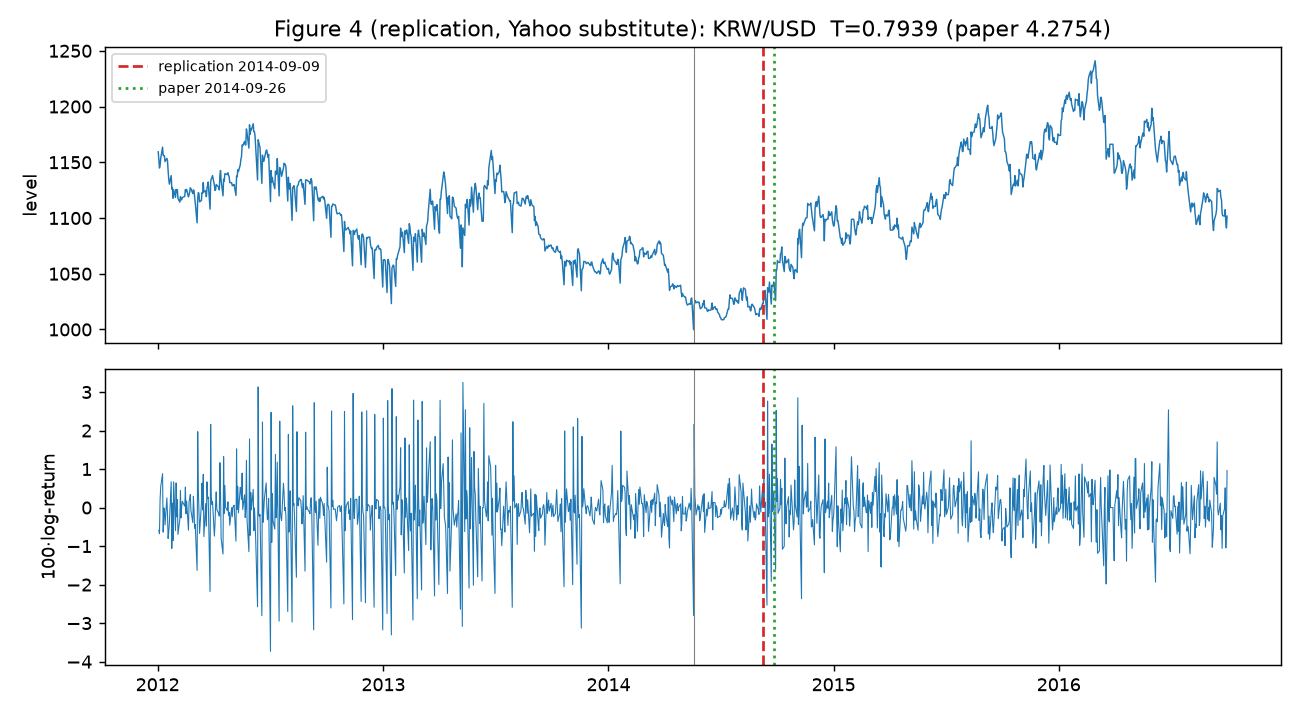

In [6]:
for f in sorted((ROOT / 'figures').glob('fig*.png')):
    print(f.name); display(Image(filename=str(f)))

In [7]:
manifest = json.loads((ROOT / 'data' / 'raw' / 'data_manifest.json').read_text())
pd.DataFrame(manifest['series']).T[['symbol', 'label', 'paper_period', 'first_date', 'last_date', 'n_levels', 'sha256']]

,symbol,label,paper_period,first_date,last_date,n_levels,sha256
sp500,^GSPC,SOURCE_SUBSTITUTED,"[2012-01-03, 2016-09-30]",2012-01-03,2016-09-30,1195,4bfa8e263582a65bc06b48b32543a5f48503eac74b40e1...
kospi,^KS11,SOURCE_SUBSTITUTED,"[2012-10-02, 2019-06-28]",2012-10-02,2019-06-28,1653,840e5443ebb49b9ef5f560c14f2457be115e4cca27406b...
krw_usd,KRW=X,SOURCE_SUBSTITUTED,"[2012-01-02, 2016-09-30]",2012-01-02,2016-09-30,1238,04d0f78ee0ab66afe3f257ed57f8ddcdce67f67a672837...


## 3. (감사 추가) 집계 정합성 — `reports/STATISTICAL_ACCOUNTING_AUDIT.md`
셀 = 원문 135칸. 조건부 기각률 + 실패율 + Wilson 95% CI. 45행 평균은 서술 통계일 뿐.

In [8]:
audit = json.loads((ROOT / 'results' / 'accounting_audit.json').read_text())
ovr = pd.read_csv(ROOT / 'reports' / 'ORIGINAL_VS_REPRODUCED.csv')
print({l: audit['lanes'][l] for l in audit['lanes']}); print(audit['paired_A_vs_B_n500'])
ovr[['table', 'label', 'n', 'paper', 'clip_status', 'clip_rate_cond_ok', 'clip_ci_lo', 'clip_ci_hi', 'raise_rate_cond_ok', 'raise_fail_rate', 'recursive_rate_cond_ok']].head(20)

{'clip': {'files': 1216, 'rows': 52900, 'duplicate_case_n_rep': 0, 'incomplete_or_misnumbered_chunks': []}, 'raise': {'files': 90, 'rows': 4500, 'duplicate_case_n_rep': 0, 'incomplete_or_misnumbered_chunks': []}, 'recursive': {'files': 180, 'rows': 4500, 'duplicate_case_n_rep': 0, 'incomplete_or_misnumbered_chunks': []}}
{'size': {'pairs': 500, 'A_only_reject': 0, 'B_only_reject': 18, 'mcnemar_exact_p': 7.62939453125e-06}, 'power': {'pairs': 4000, 'A_only_reject': 51, 'B_only_reject': 720, 'mcnemar_exact_p': 3.5762944957446895e-152}}


,table,label,n,paper,clip_status,clip_rate_cond_ok,clip_ci_lo,clip_ci_hi,raise_rate_cond_ok,raise_fail_rate,recursive_rate_cond_ok
0,1,size,500,0.023,COMPLETE_1000,0.000,0.0000,0.0038,0.0000,0.01,0.05
1,1,size,1000,0.038,PARTIAL_100,0.000,0.0000,0.0370,NaN,NaN,NaN
2,1,size,2000,0.055,PARTIAL_100,0.000,0.0000,0.0370,NaN,NaN,NaN
3,1,omega=1,500,0.761,COMPLETE_1000,0.284,0.2569,0.3127,0.2947,0.05,0.63
4,1,omega=1,1000,0.826,PARTIAL_100,0.450,0.3561,0.5476,NaN,NaN,NaN
5,1,omega=1,2000,0.956,PARTIAL_100,0.780,0.6893,0.8500,NaN,NaN,NaN
6,1,omega=0.1,500,0.612,COMPLETE_1000,0.692,0.6627,0.7198,0.6837,0.02,0.94
7,1,omega=0.1,1000,0.792,PARTIAL_100,0.990,0.9455,0.9982,NaN,NaN,NaN
8,1,omega=0.1,2000,0.970,PARTIAL_100,1.000,0.9630,1.0000,NaN,NaN,NaN
9,1,"alpha=0.1,beta=0.2",500,0.355,COMPLETE_1000,0.004,0.0016,0.0102,0.0000,0.02,0.19


## 4. (감사 추가) 통제 ablation — 같은 DGP 경로(sha256) 위 한 요인씩, 기준점 A·B 각각 (n=500, 300회)

In [9]:
abl = pd.read_csv(ROOT / 'reports' / 'ABLATION_RESULTS.csv')
abl.pivot_table(index=['test_policy', 'variant'], columns='case_id', values='reject_rate', sort=False).round(3)

case_id                           t1_size  t5_size  t1_omega_07_alpha_01  \
test_policy variant                                                        
observed    baseline                0.000    0.000                 0.007   
            scaling=x_only          0.000    0.000                 0.003   
            scaling=none            0.000    0.000                 0.003   
            grid=g125               0.000    0.000                 0.000   
            kernel=e1071_literal    0.000    0.000                 0.000   
            scale_factor=100        0.000    0.000                 0.007   
            nonpos=raise            0.000    0.000                 0.007   
            change_at=series_mid      NaN      NaN                 0.000   
            burn_in=0               0.000    0.000                 0.000   
            burn_in=0,init_x4       0.000    0.000                 0.000   
recursive   baseline                0.047    0.007                 0.133   
            scaling=x_only          0.037    0.010                 0.143   
            scaling=none            0.030    0.003                 0.120   
            grid=g125               0.047    0.003                 0.140   
            kernel=e1071_literal    0.057    0.033                 0.133   
            scale_factor=100        0.047    0.007                 0.137   
            nonpos=raise            0.048    0.003                 0.136   
            change_at=series_mid      NaN      NaN                 0.003   
            burn_in=0               0.040    0.020                 0.097   
            burn_in=0,init_x4       0.043    0.017                 0.097   

case_id                           t2_omega_1  t4_omega_01  
test_policy variant                                        
observed    baseline                   0.027        0.997  
            scaling=x_only             0.020        0.997  
            scaling=none               0.060        0.990  
            grid=g125                  0.027        1.000  
            kernel=e1071_literal       0.020        0.993  
            scale_factor=100           0.027        0.997  
            nonpos=raise               0.027        1.000  
            change_at=series_mid       0.003        0.080  
            burn_in=0                  0.033        0.993  
            burn_in=0,init_x4          0.037        0.990  
recursive   baseline                   0.227        0.970  
            scaling=x_only             0.223        0.987  
            scaling=none               0.427        0.970  
            grid=g125                  0.223        0.983  
            kernel=e1071_literal       0.253        0.977  
            scale_factor=100           0.227        0.970  
            nonpos=raise               0.226        1.000  
            change_at=series_mid       0.043        0.183  
            burn_in=0                  0.243        0.990  
            burn_in=0,init_x4          0.223        0.990

In [10]:
abl.groupby(['test_policy', 'variant'], sort=False)[['mean_lrv_ratio', 'mean_r2_sigma_vs_recent4', 'max_abs_dstat_vs_baseline', 'sec_per_rep']].mean().round(4)

mean_lrv_ratio  mean_r2_sigma_vs_recent4  \
test_policy variant                                                          
observed    baseline                      0.8491                    0.7527   
            scaling=x_only                0.8890                    0.7553   
            scaling=none                  0.8935                    0.7369   
            grid=g125                     0.8490                    0.7569   
            kernel=e1071_literal          0.8378                    0.7863   
            scale_factor=100              0.8488                    0.7528   
            nonpos=raise                  0.8462                    0.7538   
            change_at=series_mid          0.8837                    0.6875   
            burn_in=0                     0.8546                    0.7490   
            burn_in=0,init_x4             0.8539                    0.7552   
recursive   baseline                      1.2753                    0.6019   
            scaling=x_only                1.2938                    0.6181   
            scaling=none                  1.2996                    0.5976   
            grid=g125                     1.2764                    0.6031   
            kernel=e1071_literal          1.3353                    0.6261   
            scale_factor=100              1.2748                    0.6021   
            nonpos=raise                  1.2770                    0.6083   
            change_at=series_mid          1.1940                    0.5258   
            burn_in=0                     1.2924                    0.5998   
            burn_in=0,init_x4             1.2809                    0.6041   

                                  max_abs_dstat_vs_baseline  sec_per_rep  
test_policy variant                                                       
observed    baseline                                 0.0000       0.2372  
            scaling=x_only                           1.1419       0.1856  
            scaling=none                             1.1472       0.2204  
            grid=g125                                0.8500       0.8530  
            kernel=e1071_literal                     0.9472       0.1784  
            scale_factor=100                         0.0724       0.2506  
            nonpos=raise                             0.0000       0.2402  
            change_at=series_mid                        NaN       0.2350  
            burn_in=0                                   NaN       0.2296  
            burn_in=0,init_x4                           NaN       0.2278  
recursive   baseline                                 0.0000       0.3974  
            scaling=x_only                           2.2616       0.2844  
            scaling=none                             2.8187       0.2220  
            grid=g125                                2.0563       1.0012  
            kernel=e1071_literal                     2.5717       0.3398  
            scale_factor=100                         0.5119       0.4248  
            nonpos=raise                             0.0000       0.3912  
            change_at=series_mid                        NaN       0.3923  
            burn_in=0                                   NaN       0.4056  
            burn_in=0,init_x4                           NaN       0.3690

## 5. (감사 추가) 실증 원문 대비 — SOURCE_SUBSTITUTED, 임계값 1.3397 미만은 비유의

In [11]:
pd.read_csv(ROOT / 'reports' / 'EMPIRICAL_ORIGINAL_VS_REPRODUCED.csv')[['series', 'training', 'test_policy', 'nonpos_policy', 'paper_T', 'repl_T', 'repl_reject', 'paper_date', 'repl_date']]

,series,training,test_policy,nonpos_policy,paper_T,repl_T,repl_reject,paper_date,repl_date
0,sp500,first half (2012-01-04..2014-05-20),A observed-proxy,raise,2.4751,0.7540,False,2015-08-18,2015-06-26
1,sp500,first half (2012-01-04..2014-05-20),A observed-proxy,clip,2.4751,0.7540,False,2015-08-18,2015-06-26
2,sp500,first half (2012-01-04..2014-05-20),B recursive,clip,2.4751,1.0963,False,2015-08-18,2015-08-18
3,kospi,first half (2012-10-04..2016-02-11),A observed-proxy,raise,1.5081,0.7910,False,2018-01-22,2018-03-22
4,kospi,first half (2012-10-04..2016-02-11),A observed-proxy,clip,1.5081,0.7910,False,2018-01-22,2018-03-22
5,kospi,first half (2012-10-04..2016-02-11),B recursive,clip,1.5081,1.1071,False,2018-01-22,2017-11-24
6,krw_usd,first half (2012-01-03..2014-05-19),A observed-proxy,raise,4.2754,0.7939,False,2014-09-26,2014-09-09
7,krw_usd,first half (2012-01-03..2014-05-19),A observed-proxy,clip,4.2754,0.7939,False,2014-09-26,2014-09-09
8,krw_usd,first half (2012-01-03..2014-05-19),B recursive,clip,4.2754,1.0238,False,2014-09-26,2014-09-09
9,sp500,paper example 2012-04-02..2014-04-16 (SUSPECTE...,A observed-proxy,clip,2.4751,0.8134,False,2015-08-18,2015-06-26
